# Control óptimo de EDOs — Clase 6
**Varios estados. Modelos epidemiológicos**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

In [2]:
def rk4(F, y0, t):
    """Integra y' = F(t, y) en la grilla t con Runge-Kutta 4."""
    y = np.zeros((len(t), np.size(y0))); y[0] = y0
    for k in range(len(t) - 1):
        h = t[k+1] - t[k]
        k1 = F(t[k], y[k]); k2 = F(t[k] + h/2, y[k] + h/2*k1)
        k3 = F(t[k] + h/2, y[k] + h/2*k2); k4 = F(t[k] + h, y[k] + h*k3)
        y[k+1] = y[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return y

def fbsm(f, dlam, ucalc, x0, lamT, T, N=1000, m=1, u0=None,
         omega=0.5, tol=1e-3, maxit=2000, historia=False):
    """Forward-Backward Sweep (Lenhart & Workman, cap. 4). Problema de MÁXIMO.
    f(t,x,u)        -> x'                  (arreglos de dimensión n)
    dlam(t,x,u,lam) -> lam' = -H_x
    ucalc(t,x,lam)  -> control dado por el PMP (dimensión m)
    lamT(xT)        -> lam(T) (condición de transversalidad)
    Devuelve un diccionario con t, x, u, lam, iteraciones (y la historia de u)."""
    t = np.linspace(0, T, N+1); h = T/N
    x0 = np.atleast_1d(np.asarray(x0, float)); n = len(x0)
    u = np.zeros((N+1, m)) if u0 is None else np.array(u0, float).reshape(N+1, m)
    x = np.zeros((N+1, n)); lam = np.zeros((N+1, n)); hist = []
    rel = lambda a, b: np.sum(np.abs(a - b)) / max(np.sum(np.abs(a)), 1e-12)
    for it in range(maxit):
        uo, xo, lo = u.copy(), x.copy(), lam.copy()
        x[0] = x0                                   # Paso 1: estado hacia adelante
        for k in range(N):
            um = 0.5*(u[k] + u[k+1])
            k1 = f(t[k], x[k], u[k]); k2 = f(t[k]+h/2, x[k]+h/2*k1, um)
            k3 = f(t[k]+h/2, x[k]+h/2*k2, um); k4 = f(t[k]+h, x[k]+h*k3, u[k+1])
            x[k+1] = x[k] + h/6*(k1 + 2*k2 + 2*k3 + k4)
        lam[N] = lamT(x[N])                         # Paso 2: adjunto hacia atrás
        for k in range(N, 0, -1):
            um = 0.5*(u[k] + u[k-1]); xm = 0.5*(x[k] + x[k-1])
            k1 = dlam(t[k], x[k], u[k], lam[k])
            k2 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k1)
            k3 = dlam(t[k]-h/2, xm, um, lam[k] - h/2*k2)
            k4 = dlam(t[k]-h, x[k-1], u[k-1], lam[k] - h*k3)
            lam[k-1] = lam[k] - h/6*(k1 + 2*k2 + 2*k3 + k4)
        u1 = np.array([np.atleast_1d(ucalc(t[k], x[k], lam[k])) for k in range(N+1)]).reshape(N+1, m)
        u = omega*u1 + (1 - omega)*uo               # Paso 3: actualizar con relajación
        if historia: hist.append(u.copy())
        if it > 0 and max(rel(u, uo), rel(x, xo), rel(lam, lo)) < tol:   # Paso 4
            break
    return dict(t=t, x=x, u=u, lam=lam, iters=it+1, hist=hist)

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

## 1. SIS: el teorema del umbral
$\dot I=\beta(1-I)I-(\gamma+\mu)I$; si $\mathcal R_0=\beta/(\gamma+\mu)>1$, $I\to1-1/\mathcal R_0$.

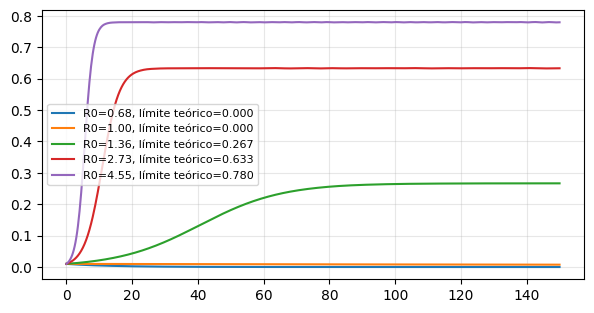

In [3]:
mu, gam = 0.02, 0.2
t = np.linspace(0, 150, 600)
for beta in [0.15, 0.22, 0.3, 0.6, 1.0]:
    R0 = beta/(gam + mu)
    s = solve_ivp(lambda t, I: beta*(1 - I)*I - (gam + mu)*I, [0, 150], [0.01], t_eval=t)
    plt.plot(t, s.y[0], label=f'R0={R0:.2f}, límite teórico={max(0, 1 - 1/R0):.3f}')
plt.legend(fontsize=8); plt.show()

## 2. SIR: pico de infectados y tamaño final (Hethcote)
$I_{\max}=1-R(0)-\frac1{\mathcal R_0}-\frac{\ln(\mathcal R_0S(0))}{\mathcal R_0}$ y $S_\infty$ raíz de $1-R(0)-S_\infty+\frac{\ln(S_\infty/S(0))}{\mathcal R_0}=0$.

In [4]:
beta, gam = 0.3, 0.1; R0 = beta/gam; S0, I0, Rr0 = 0.99, 0.01, 0.0
s = solve_ivp(lambda t, y: [-beta*y[0]*y[1], beta*y[0]*y[1] - gam*y[1], gam*y[1]],
              [0, 400], [S0, I0, Rr0], rtol=1e-10, atol=1e-12, dense_output=True)
tt = np.linspace(0, 400, 20001); S, I, R = s.sol(tt)
Imax_teo = 1 - Rr0 - 1/R0 - np.log(R0*S0)/R0
Sinf_teo = brentq(lambda z: 1 - Rr0 - z + np.log(z/S0)/R0, 1e-9, 1/R0)
print(f'I_max: simulado {I.max():.6f}   teórico {Imax_teo:.6f}')
print(f'S_inf: simulado {S[-1]:.6f}   teórico {Sinf_teo:.6f}')

I_max: simulado 0.303813   teórico 0.303813
S_inf: simulado 0.058797   teórico 0.058797


## 3. SEIR con vacunación (L&W Lab / Aronna)
Estados $(S,E,I,N)$; $R=N-S-E-I$. Objetivo $\min\int_0^T(AI+u^2)$, $0\le u\le0.9$.
Las ecuaciones adjuntas están en las diapositivas.

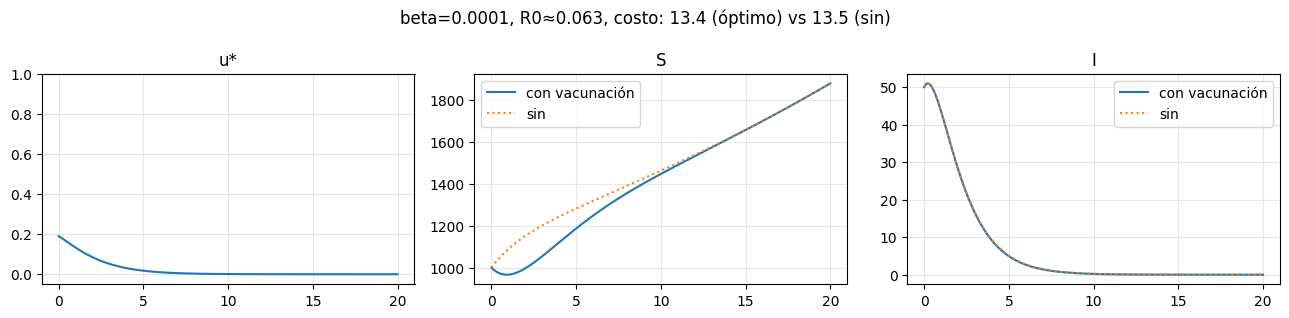

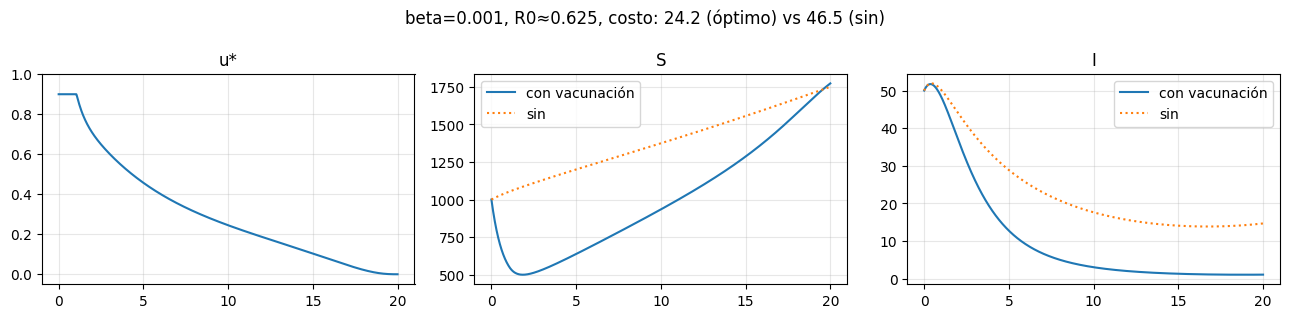

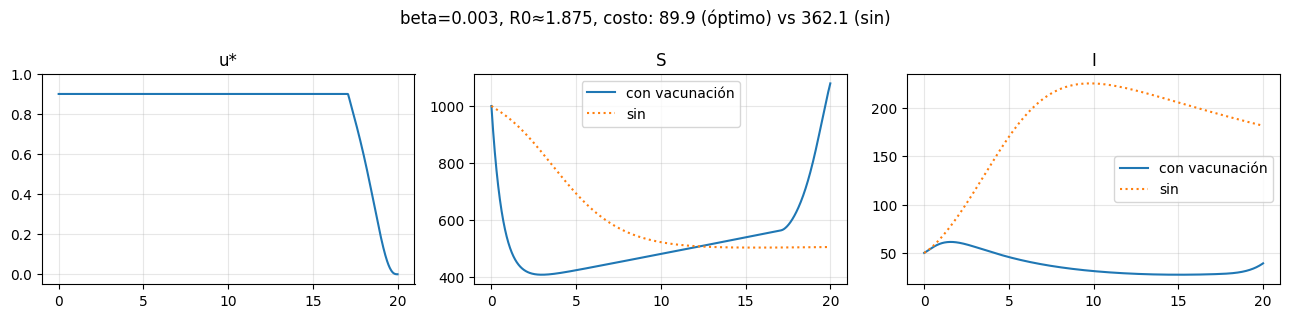

In [5]:
def seir(beta, A=0.1, umax=0.9, T=20.0, mu=0.525, delta=0.5, eps=0.5, gam=0.1, alfa=0.2,
         x0=(1000, 100, 50, 1165), sin_control=False):
    def f(t, x, u):
        S, E, I, N = x; u = u[0]
        return np.array([mu*N - delta*S - beta*S*I - u*S, beta*S*I - (eps + delta)*E,
                         eps*E - (delta + alfa + gam)*I, (mu - delta)*N - alfa*I])
    def dlam(t, x, u, l):
        S, E, I, N = x; u = u[0]; lS, lE, lI, lN = l
        return np.array([lS*(delta + beta*I + u) - lE*beta*I,
                         lE*(eps + delta) - lI*eps,
                         A + (lS - lE)*beta*S + lI*(delta + alfa + gam) + lN*alfa,
                         -lS*mu - lN*(mu - delta)])
    ucalc = (lambda t, x, l: 0.0) if sin_control else (lambda t, x, l: np.clip(-l[0]*x[0]/2, 0, umax))
    r = fbsm(f, dlam, ucalc, x0, lambda xT: np.zeros(4), T, maxit=1 if sin_control else 2000)
    r['J'] = integral(A*r['x'][:, 2] + r['u'][:, 0]**2, r['t'])
    return r

def R0_seir(beta, S=1000, eps=0.5, delta=0.5, alfa=0.2, gam=0.1):
    return beta*eps*S/((eps + delta)*(delta + alfa + gam))

def graficar(beta, **kw):
    opt, sin = seir(beta, **kw), seir(beta, sin_control=True, **kw)
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2)); t = opt['t']
    ax[0].plot(t, opt['u'][:, 0]); ax[0].set_title('u*'); ax[0].set_ylim(-0.05, 1)
    for i, nom, a in [(0, 'S', ax[1]), (2, 'I', ax[2])]:
        a.plot(t, opt['x'][:, i], label='con vacunación'); a.plot(t, sin['x'][:, i], ':', label='sin')
        a.set_title(nom); a.legend()
    fig.suptitle(f'beta={beta}, R0≈{R0_seir(beta):.3f}, costo: {opt["J"]:.1f} (óptimo) vs {sin["J"]:.1f} (sin)')
    plt.tight_layout(); plt.show()

for beta in [0.0001, 0.001, 0.003]:
    graficar(beta)

## Para explorar
1. Cambiar el peso $A$ (p. ej. $A\in\{0.01, 0.1, 1, 10\}$) con $\beta=0.001$. ¿Cómo cambia $u^*$?
2. Cambiar la cota $u_{\max}$. ¿Cuándo deja de ser activa?
3. **Desafío:** SIR con distanciamiento, $\beta\to(1-u)\beta$, $u\in[0,0.7]$, objetivo $\min\int(I+Bu^2)$.
   Derivar el PMP y programarlo con `fbsm` (2 estados).